# Trực quan hóa 5 cách mã hóa AMO

Nguồn dữ liệu: `results/data/amo_120s.csv`; notebook phân tích toàn bộ 113 đồ thị thuộc `hb_33` và `hb_80`, tương ứng 565 dòng (mỗi đồ thị chạy 5 AMO; Pairwise + Incremental, giới hạn 120 giây/lượt).

Chạy notebook từ trên xuống dưới bằng kernel Python của `.venv`. Hai hình được lưu thêm vào `results/visualization/png/` để đưa vào báo cáo. Biểu đồ cột dùng [`cnsplots`](https://cnsplots.farid.one/latest/); performance profile dùng Matplotlib.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import cnsplots as cns

VALID_STATUSES = {"OPTIMAL", "FEASIBLE"}
AMO_ORDER = ["Binomial", "Binary", "Commander", "Product", "Sequential"]
root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "results/data/amo_120s.csv").is_file()), None)
if root is None:
    raise FileNotFoundError("Không tìm thấy results/data/amo_120s.csv; hãy mở notebook trong dự án BMP")
csv_path = root / "results/data/amo_120s.csv"
figure_dir = root / "results/visualization/png"
figure_dir.mkdir(parents=True, exist_ok=True)
print("Đang đọc:", csv_path)


Đang đọc: D:\EXP\year-3-semester-1\Contemporary-issues-in-computer-science\Bandwidth-Minimization-Problem\results\data\amo_120s.csv


## Đọc và kiểm tra dữ liệu

Một instance phải có đúng một dòng cho mỗi AMO. Bandwidth càng **nhỏ** càng tốt. `OPTIMAL` nghĩa là solver đã chứng minh không thể có bandwidth nhỏ hơn; `FEASIBLE` chỉ có nghiệm khả thi hiện tốt nhất khi hết thời gian.

Chỉ `OPTIMAL` và `FEASIBLE` được dùng để tính nghiệm tốt nhất, đếm số lần đạt mốc và vẽ profile. Bandwidth của `ERROR`/`TIMEOUT` bị loại hoàn toàn. Profile giữ mẫu số chung là 113 đồ thị; kết quả không hợp lệ không đóng góp vào đường cong.


In [2]:
amo = pd.read_csv(csv_path)
required = {"instance", "cardinality", "status", "bandwidth"}
if not required.issubset(amo.columns):
    raise ValueError(f"CSV thiếu cột: {required - set(amo.columns)}")
instance_names = {
    path.name.removesuffix(".mtx.rnd")
    for group in ("hb_33", "hb_80")
    for path in (root / "data" / group).glob("*.mtx.rnd")
}
if not instance_names:
    raise ValueError("Không tìm thấy đồ thị trong data/hb_33 và data/hb_80")
instance_count = len(instance_names)
expected_rows = instance_count * len(AMO_ORDER)
if len(amo) != expected_rows or set(amo["instance"]) != instance_names:
    raise ValueError(
        f"Cần đúng {expected_rows} dòng cho {instance_count} đồ thị "
        f"và {len(AMO_ORDER)} AMO thuộc cả hb_33 và hb_80"
    )
if set(amo["cardinality"]) != set(AMO_ORDER):
    raise ValueError("Danh sách AMO không khớp năm cấu hình cần so sánh")
if amo.duplicated(["instance", "cardinality"]).any():
    raise ValueError("Có cặp instance/AMO bị lặp")
if not amo.groupby("instance")["cardinality"].nunique().eq(len(AMO_ORDER)).all():
    raise ValueError("Có đồ thị thiếu một cách mã hóa AMO")
if not amo["status"].isin(["OPTIMAL", "FEASIBLE", "TIMEOUT", "ERROR"]).all():
    raise ValueError("Trạng thái solver không hợp lệ")
# Chỉ nghiệm OPTIMAL/FEASIBLE được tham gia mọi phép so sánh chất lượng.
# Không đọc hoặc kiểm tra bandwidth dự phòng của ERROR/TIMEOUT như một nghiệm.
valid_amo = amo.loc[amo["status"].isin(VALID_STATUSES)].copy()
valid_amo["bandwidth"] = pd.to_numeric(valid_amo["bandwidth"], errors="raise")
if valid_amo["bandwidth"].isna().any() or valid_amo["bandwidth"].lt(0).any():
    raise ValueError("Nghiệm OPTIMAL/FEASIBLE phải có bandwidth không âm và không thiếu")
wide = valid_amo.pivot(index="instance", columns="cardinality", values="bandwidth").reindex(
    index=sorted(instance_names), columns=AMO_ORDER
)
best_by_instance = wide.min(axis=1)
valid_counts = valid_amo.groupby("cardinality").size().reindex(AMO_ORDER, fill_value=0)
print(f"Đã kiểm tra: {len(amo)} dòng, {instance_count} đồ thị, {len(AMO_ORDER)} AMO")
print(f"Chỉ dùng {len(valid_amo)} dòng OPTIMAL/FEASIBLE; loại {len(amo) - len(valid_amo)} dòng ERROR/TIMEOUT khỏi bandwidth")
display(valid_counts.rename("Số nghiệm OPTIMAL/FEASIBLE"))


Đã kiểm tra: 565 dòng, 113 đồ thị, 5 AMO
Chỉ dùng 487 dòng OPTIMAL/FEASIBLE; loại 78 dòng ERROR/TIMEOUT khỏi bandwidth


cardinality
Binomial       41
Binary        107
Commander     113
Product       113
Sequential    113
Name: Số nghiệm OPTIMAL/FEASIBLE, dtype: int64

## Hình 1 — Số lần đạt nghiệm tốt nhất và chứng minh OPTIMAL

Với từng đồ thị, lấy bandwidth nhỏ nhất trong **các nghiệm OPTIMAL/FEASIBLE của 5 AMO trong CSV này**. Mỗi AMO đạt đúng giá trị ấy được tính một lần; nếu hòa, tất cả AMO hòa đều được tính. Cột `OPTIMAL` đếm trực tiếp trạng thái trong CSV. Vì có hòa, tổng các cột màu xanh có thể lớn hơn tổng số đồ thị.


,Đạt bandwidth tốt nhất,Chứng minh OPTIMAL
cardinality,,
Binomial,8,3
Binary,16,4
Commander,16,4
Product,83,5
Sequential,34,7


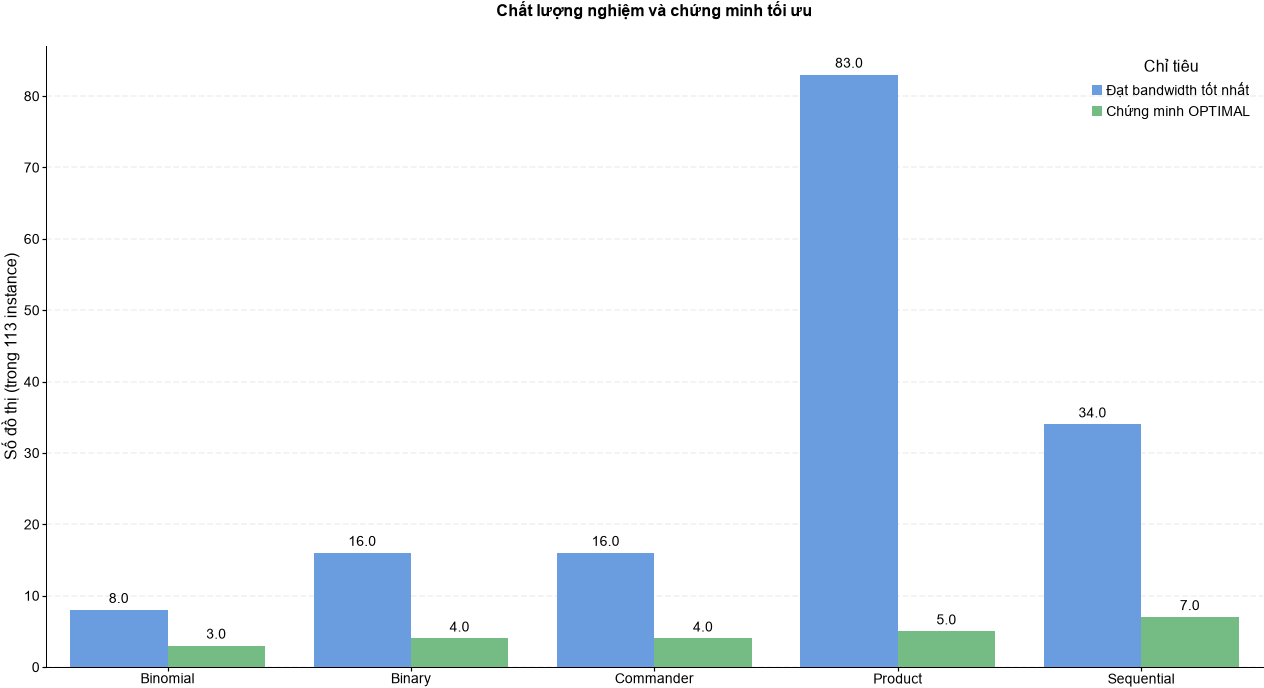

In [3]:
best_count = wide.eq(best_by_instance, axis=0).sum().reindex(AMO_ORDER).astype(int)
optimal_count = (amo.assign(is_optimal=amo["status"].eq("OPTIMAL"))
                 .groupby("cardinality")["is_optimal"].sum()
                 .reindex(AMO_ORDER).astype(int))
summary = pd.DataFrame({"Đạt bandwidth tốt nhất": best_count,
                        "Chứng minh OPTIMAL": optimal_count})
display(summary)

bars = (summary.rename_axis("AMO").reset_index()
        .melt(id_vars="AMO", var_name="Chỉ tiêu", value_name="Số đồ thị"))
fig = cns.figure(9, 5, unit="in")
# cns.figure bật nền xuất trong suốt; dùng nền trắng cho PNG và hình trong notebook.
plt.rcParams.update({"savefig.transparent": False, "savefig.facecolor": "white"})
ax = cns.barplot(data=bars, x="AMO", y="Số đồ thị", hue="Chỉ tiêu",
                 order=AMO_ORDER, hue_order=list(summary.columns),
                 palette={"Đạt bandwidth tốt nhất": "#579BF2",
                          "Chứng minh OPTIMAL": "#69C77D"},
                 errorbar=None, dodge=True, add_tip=True)
ax.set_title("Chất lượng nghiệm và chứng minh tối ưu", pad=15)
ax.set_xlabel("")
ax.set_ylabel(f"Số đồ thị (trong {len(wide)} instance)")
ax.set_ylim(0, max(summary.max()) + 4)
ax.yaxis.grid(True, alpha=0.18, linestyle="--")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(figure_dir / "amo_grouped_bars.png", dpi=220, bbox_inches="tight",
            facecolor="white", transparent=False)
plt.show()


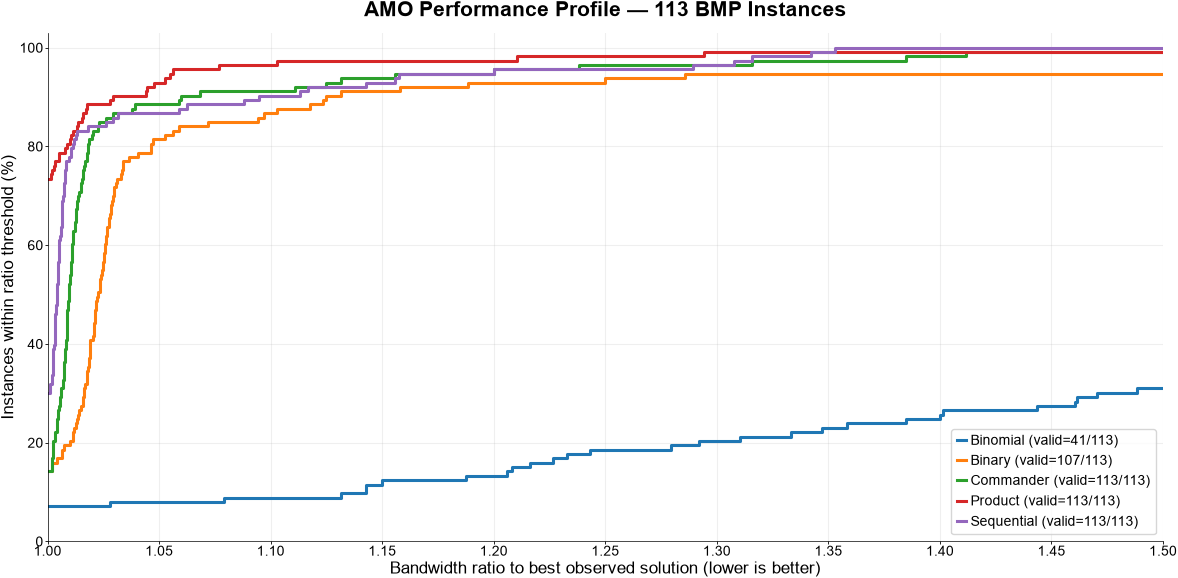

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Chỉ dùng nghiệm OPTIMAL/FEASIBLE thuộc hb_33 và hb_80.
df = valid_amo.copy()
order = AMO_ORDER

# 3. Mốc tốt nhất cũng chỉ lấy từ nghiệm OPTIMAL/FEASIBLE.
# Với bandwidth tốt nhất bằng 0, chỉ bandwidth 0 nhận ratio 1.
best = df.groupby("instance")["bandwidth"].min()
best_for_row = df["instance"].map(best)
df["ratio"] = np.inf
positive_best = best_for_row.gt(0)
df.loc[positive_best, "ratio"] = (
    df.loc[positive_best, "bandwidth"] / best_for_row.loc[positive_best]
)
df.loc[best_for_row.eq(0) & df["bandwidth"].eq(0), "ratio"] = 1.0

# 4. Giữ nguyên màu của biểu đồ gốc
colors = {
    "Binomial": "tab:blue",
    "Binary": "tab:orange",
    "Commander": "tab:green",
    "Product": "tab:red",
    "Sequential": "tab:purple",
}

# 5. Vẽ một biểu đồ duy nhất
fig, ax = plt.subplots(figsize=(12, 6))

for method in order:
    ratios = np.sort(
        df.loc[
            df["cardinality"] == method,
            "ratio"
        ].to_numpy()
    )

    ratios = ratios[np.isfinite(ratios)]
    # Mẫu số chung 113; không chuẩn hóa riêng theo số nghiệm của từng AMO.
    # ERROR/TIMEOUT không có ratio và không được tính vào tử số.
    x = np.unique(np.r_[1.0, ratios[(ratios >= 1.0) & (ratios <= 1.5)], 1.5])
    y = np.searchsorted(ratios, x, side="right") / instance_count * 100

    ax.step(
        x,
        y,
        where="post",
        linewidth=2.2,
        color=colors[method],
        label=f"{method} (valid={int(valid_counts[method])}/{instance_count})",
    )

# 6. Giới hạn X từ 1.0 đến 1.5
ax.set_xlim(1.0, 1.5)
ax.set_ylim(0, 103)

ax.set_xticks(np.arange(1.0, 1.51, 0.05))

ax.set_xlabel(
    "Bandwidth ratio to best observed solution (lower is better)",
    fontsize=12,
)

ax.set_ylabel(
    "Instances within ratio threshold (%)",
    fontsize=12,
)

ax.set_title(
    f"AMO Performance Profile — {len(wide)} BMP Instances",
    fontsize=15,
    pad=12,
)

ax.grid(True, alpha=0.2)
ax.tick_params(labelsize=10)

# Legend không che dữ liệu
ax.legend(
    loc="lower right",
    fontsize=10,
    frameon=True,
)

plt.tight_layout()

# 7. Xuất hình
output_dir = figure_dir
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "amo_performance_profile.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    transparent=False,
)

plt.show()